# ECE1553 — Applied Deep Learning 
## Midterm Review

### Learning Goals

1. Connect tensors
2. models 
3. gradients and optimizers 
4. generalization, regularization and dropout
5. Basics of CNNs


In [33]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)


## 1 · Shapes, layers, and nonlinearities
A batch of $N$ observations with $D$ features is an $N\times D$ tensor. A dense layer computes $Z=XW^\top+b$; its output is $N\times H$ for $H$ neurons. Stacking **only linear layers** (i.e., nn.Linear layers which computes affine transformation) without nonlinear activations is still equivalent to a single affine layer. Nonlinear activations (ReLU, Tanh) allow curved decision boundaries and nonlinear function approximation.

In [34]:
X = torch.randn(8, 3)
layer = nn.Linear(3, 5)
Z = layer(X)
print('X:', tuple(X.shape), 'weight:', tuple(layer.weight.shape), 'Z:', tuple(Z.shape))
print('Parameter count:', sum(p.numel() for p in layer.parameters()))
assert Z.shape == (8, 5)

X: (8, 3) weight: (5, 3) Z: (8, 5)
Parameter count: 20


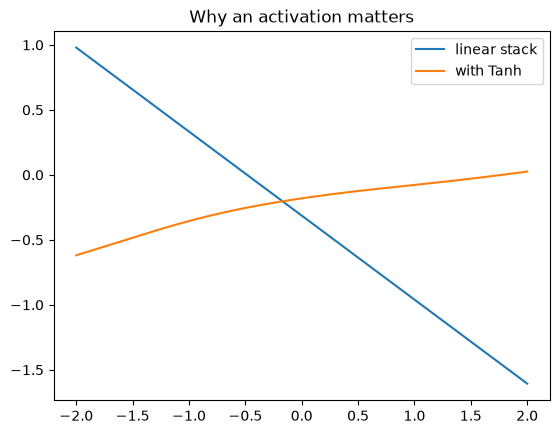

In [35]:
x_grid = torch.linspace(-2, 2, 300).unsqueeze(1)
torch.manual_seed(SEED)
linear_stack = nn.Sequential(nn.Linear(1, 12), nn.Linear(12, 1))
nonlinear_stack = nn.Sequential(nn.Linear(1, 12), nn.Tanh(), nn.Linear(12, 1))
with torch.no_grad():
    plt.plot(x_grid, linear_stack(x_grid), label='linear stack')
    plt.plot(x_grid, nonlinear_stack(x_grid), label='with Tanh')
plt.legend(); plt.title('Why an activation matters'); plt.show()

**Checkpoint:** If $X$ has shape $(64,10)$ and `nn.Linear(10,4)` is applied, what are the output shape and number of trainable parameters? Why does adding a second linear layer not create a nonlinear model?

<details>
<summary><strong>Answer</strong></summary>

The output shape is **`(64, 4)`**: the layer preserves the batch dimension and maps each 10-feature sample to 4 features. The layer has $10 \times 4 = 40$ weights and $4$ biases, for **44 trainable parameters** in total.

Without an activation between them, two linear layers still represent a single affine transformation:

$$W_2(W_1X + b_1) + b_2 = (W_2W_1)X + (W_2b_1 + b_2).$$

Therefore, adding a second linear layer increases the parameterization but does not make the model nonlinear; a nonlinear activation such as `ReLU` is needed between the layers.

</details>

## 2 · Losses, autograd, and training
Regression commonly uses mean squared error. Binary classification can use `BCEWithLogitsLoss` (raw logits and binary targets); multiclass classification uses `CrossEntropyLoss` (raw class logits and integer class labels). **Do not apply Softmax before `CrossEntropyLoss`.**

Backpropagation computes gradients via the chain rule. The standard sequence is: clear old gradients → forward pass → compute loss → backward pass → optimizer step.

In [36]:
w = torch.tensor(0.0, requires_grad=True)
loss = (w - 3.0)**2
loss.backward()
print('Loss:', loss.item(), 'dLoss/dw:', w.grad.item())
assert w.grad.item() == -6.0

Loss: 9.0 dLoss/dw: -6.0


Learned weight and bias: 2.9568705558776855 2.0003929138183594


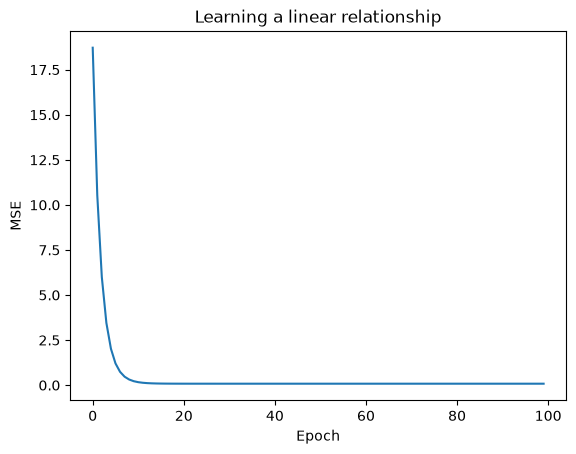

In [37]:
x = torch.linspace(-2, 2, 100).unsqueeze(1)
y = 3*x + 2 + 0.3*torch.randn_like(x)
model = nn.Linear(1, 1)
opt = torch.optim.SGD(model.parameters(), lr=0.1)
history = []
for epoch in range(100):
    opt.zero_grad()
    pred = model(x)
    loss = nn.functional.mse_loss(pred, y)
    loss.backward()
    opt.step()
    history.append(loss.item())
print('Learned weight and bias:', model.weight.item(), model.bias.item())
plt.plot(history); plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.title('Learning a linear relationship'); plt.show()

## 3 · Optimizers and mini-batches
Gradient descent updates $\theta_{t+1}=\theta_t-\eta\nabla L(\theta_t)$. Full-batch GD uses all training samples per update; mini-batch SGD uses a randomly sampled subset, introducing gradient noise while allowing more frequent, cheaper updates. **An epoch** is one pass over the training set; **an update** is one optimizer step.

Momentum accumulates a moving direction from earlier gradients. Adam adapts step sizes using moving estimates of the first and second gradient moments. Performance depends on hyperparameters; Adam is not universally superior.

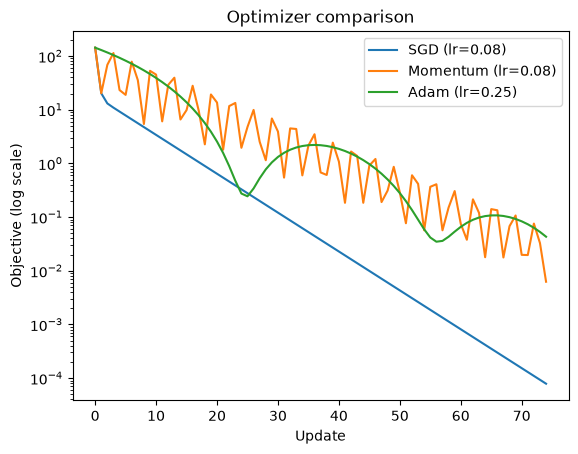

In [38]:
# Compare optimizers on the SAME two-dimensional quadratic objective.
def run_optimizer(kind, lr, steps=75):
    p = nn.Parameter(torch.tensor([-4.0, 4.0]))
    if kind == 'SGD': optimizer = torch.optim.SGD([p], lr=lr)
    elif kind == 'Momentum': optimizer = torch.optim.SGD([p], lr=lr, momentum=0.9)
    else: optimizer = torch.optim.Adam([p], lr=lr)
    losses = []
    for _ in range(steps):
        optimizer.zero_grad()
        loss = 0.5*(10*(p[0]-1)**2 + (p[1]+2)**2)
        losses.append(loss.item())
        loss.backward(); optimizer.step()
    return losses
for name, lr in [('SGD', 0.08), ('Momentum', 0.08), ('Adam', 0.25)]:
    plt.semilogy(run_optimizer(name, lr), label=f'{name} (lr={lr})')
plt.xlabel('Update'); plt.ylabel('Objective (log scale)'); plt.legend(); plt.title('Optimizer comparison'); plt.show()

In [39]:
# Mini-batch demonstration: the number of updates per epoch changes with batch size.
features = torch.randn(103, 4)
targets = torch.randint(0, 2, (103,))
for batch_size in [1, 16, 103]:
    loader = DataLoader(TensorDataset(features, targets), batch_size=batch_size, shuffle=True)
    print(f'batch size={batch_size:3d} -> {len(loader)} updates per epoch')

batch size=  1 -> 103 updates per epoch
batch size= 16 -> 7 updates per epoch
batch size=103 -> 1 updates per epoch


**Try it:** Change the learning rates above. Which optimizer oscillates or diverges first? Compare full-batch, batch size 16, and batch size 1: which produces the noisiest gradient estimate?

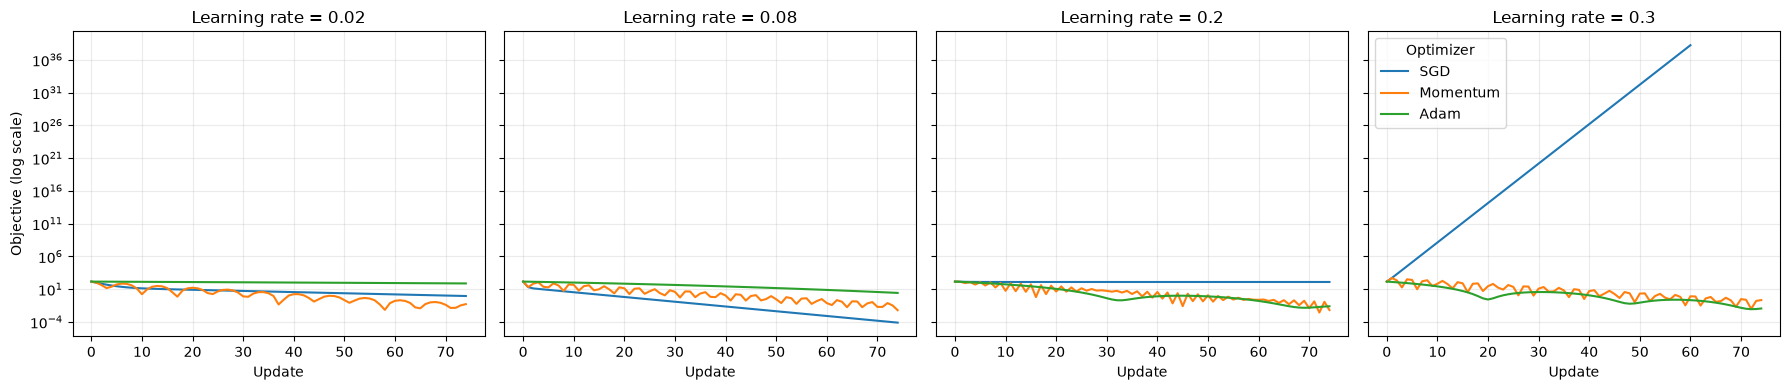

In [40]:
# Try different learning rates on the same objective and starting point.
learning_rates = [0.02, 0.08, 0.20, 0.30]  # Edit these values.
optimizer_names = ['SGD', 'Momentum', 'Adam']

fig, axes = plt.subplots(1, len(learning_rates), figsize=(18, 4), sharey=True)
for ax, lr in zip(axes, learning_rates):
    for name in optimizer_names:
        losses = run_optimizer(name, lr, steps=75)
        ax.semilogy(losses, label=name)
    ax.set_title(f'Learning rate = {lr}')
    ax.set_xlabel('Update')
    ax.grid(alpha=0.25)
axes[0].set_ylabel('Objective (log scale)')
axes[-1].legend(title='Optimizer')
plt.tight_layout()
plt.show()

In [41]:
# Quantify gradient noise without updating the model.
torch.manual_seed(SEED)
probe_model = nn.Linear(4, 2)
criterion = nn.CrossEntropyLoss()

def gradient_vector(x_batch, y_batch):
    probe_model.zero_grad()
    loss = criterion(probe_model(x_batch), y_batch)
    loss.backward()
    return torch.cat([p.grad.flatten() for p in probe_model.parameters()]).detach().clone()

full_gradient = gradient_vector(features, targets)
for batch_size in [len(features), 16, 1]:
    loader = DataLoader(TensorDataset(features, targets), batch_size=batch_size, shuffle=False)
    batch_gradients = torch.stack([gradient_vector(xb, yb) for xb, yb in loader])
    deviations = torch.linalg.vector_norm(batch_gradients - full_gradient, dim=1)
    print(f'batch size={batch_size:3d} | batches={len(loader):3d} | '
          f'mean distance from full gradient={deviations.mean():.4f} | '
          f'max distance={deviations.max():.4f}')

# The smallest batch should have the largest deviations: batch size 1 is noisiest (SGD), 
# batch size 16 is less noisy (mini-batch SGD), 
# and batch size 103 is the least noisy (full-batch gradient descent).

batch size=103 | batches=  1 | mean distance from full gradient=0.0000 | max distance=0.0000
batch size= 16 | batches=  7 | mean distance from full gradient=0.3797 | max distance=0.7816
batch size=  1 | batches=103 | mean distance from full gradient=1.5504 | max distance=5.5438


## 4 · Overfitting, model capacity, and generalization
**Training loss** measures fit to observed training data. **Validation loss** helps select hyperparameters and determine when to stop. **Test loss** estimates performance on unseen data *after* model selection. A widening train–validation gap is evidence of overfitting, though the gap alone does not prove its cause.

Model capacity describes the richness of the functions a model can represent. Higher capacity can reduce training error but may overfit when data are limited. Below, we deliberately give the models only 16 noisy training samples and evaluate them against an independent noisy validation set. The long run lets the wide model memorize the training noise, creating a clear train–validation gap.

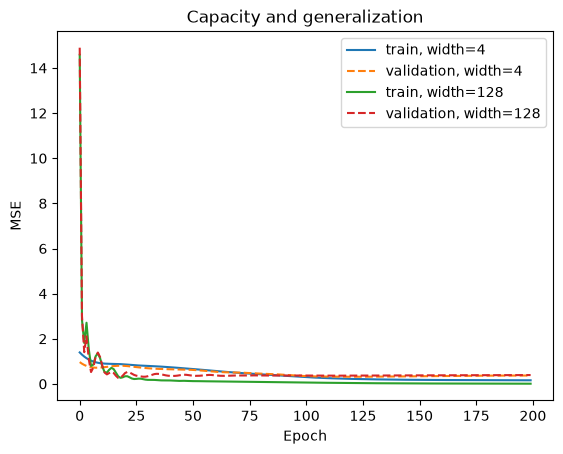

width=4: final train=0.160, validation=0.372, best validation epoch=124
width=128: final train=0.009, validation=0.392, best validation epoch=18


In [42]:
torch.manual_seed(SEED)
# A tiny, noisy training set makes memorization visible.
x_train = torch.linspace(-3, 3, 16).unsqueeze(1)
y_train = torch.sin(2*x_train) + 0.45*torch.randn_like(x_train)
x_val = torch.linspace(-3, 3, 160).unsqueeze(1)
y_val = torch.sin(2*x_val) + 0.45*torch.randn_like(x_val)

def make_regressor(width):
    return nn.Sequential(nn.Linear(1, width), nn.Tanh(), nn.Linear(width, width), nn.Tanh(), nn.Linear(width, 1))

def fit_regressor(width, epochs=200):
    torch.manual_seed(SEED)
    net = make_regressor(width)
    optimizer = torch.optim.Adam(net.parameters(), lr=0.015)
    train_curve, val_curve = [], []
    for _ in range(epochs):
        net.train(); optimizer.zero_grad()
        train_loss = nn.functional.mse_loss(net(x_train), y_train)
        train_loss.backward(); optimizer.step()
        net.eval()
        with torch.no_grad():
            train_curve.append(nn.functional.mse_loss(net(x_train), y_train).item())
            val_curve.append(nn.functional.mse_loss(net(x_val), y_val).item())
    return net, train_curve, val_curve
results = {w: fit_regressor(w) for w in [4, 128]}
for w, (_, tr, va) in results.items():
    plt.plot(tr, label=f'train, width={w}')
    plt.plot(va, '--', label=f'validation, width={w}')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.legend(); plt.title('Capacity and generalization'); plt.show()
for w, (_, tr, va) in results.items():
    print(f'width={w}: final train={tr[-1]:.3f}, validation={va[-1]:.3f}, best validation epoch={np.argmin(va)+1}')

**Checkpoint:** Why should the test set not be used to choose the best epoch? If validation loss begins increasing while training loss keeps decreasing, what training intervention could help? (Consider early stopping.)

<details>
<summary><strong>Answer</strong></summary>

The test set should be kept untouched until the model and all training choices have been finalized. Choosing the best epoch using test performance leaks information from the test set into model selection, making the final test result optimistically biased rather than an independent estimate of generalization. Use the **validation set** to choose the epoch instead.

Validation loss increasing while training loss continues to decrease is evidence of **overfitting**. Apply **early stopping**: monitor validation loss, stop after it has failed to improve for a chosen patience period, and restore the checkpoint from the epoch with the lowest validation loss.

</details>

## 5 · Dropout: training vs. inference
Dropout randomly sets activations to zero during **training** with drop probability $p$ (keep probability $1-p$). PyTorch uses **inverted dropout**: surviving activations are divided by $1-p$ during training, so no extra scaling is needed at inference. At evaluation time, dropout is disabled.

Dropout can regularize a network by discouraging excessive reliance on individual activations, but it does not guarantee improved generalization.

In [43]:
# demonstrates how dropout works in training vs. evaluation mode.
drop = nn.Dropout(p=0.5)
a = torch.ones(10000)
drop.train()
train_output = drop(a)
drop.eval()
test_output = drop(a)
# Expectation: About x% of activations were randomly set to zero, 
# which is close to the requested dropout probability p=0.5
print('Training zero fraction:', (train_output == 0).float().mean().item()) 
# Expectation: PyTorch automatically scales the remaining activations by 1/(1-p) during training, 
# so the mean of the training output is close to 1.0: 0.5(0) + 0.5(2) = 1.0
print('Training output mean:', train_output.mean().item())
# Expectation: During evaluation, dropout is disabled, so all activations are present and unchanged.
print('Evaluation unique values:', torch.unique(test_output).tolist())

Training zero fraction: 0.5044000148773193
Training output mean: 0.9911999702453613
Evaluation unique values: [1.0]


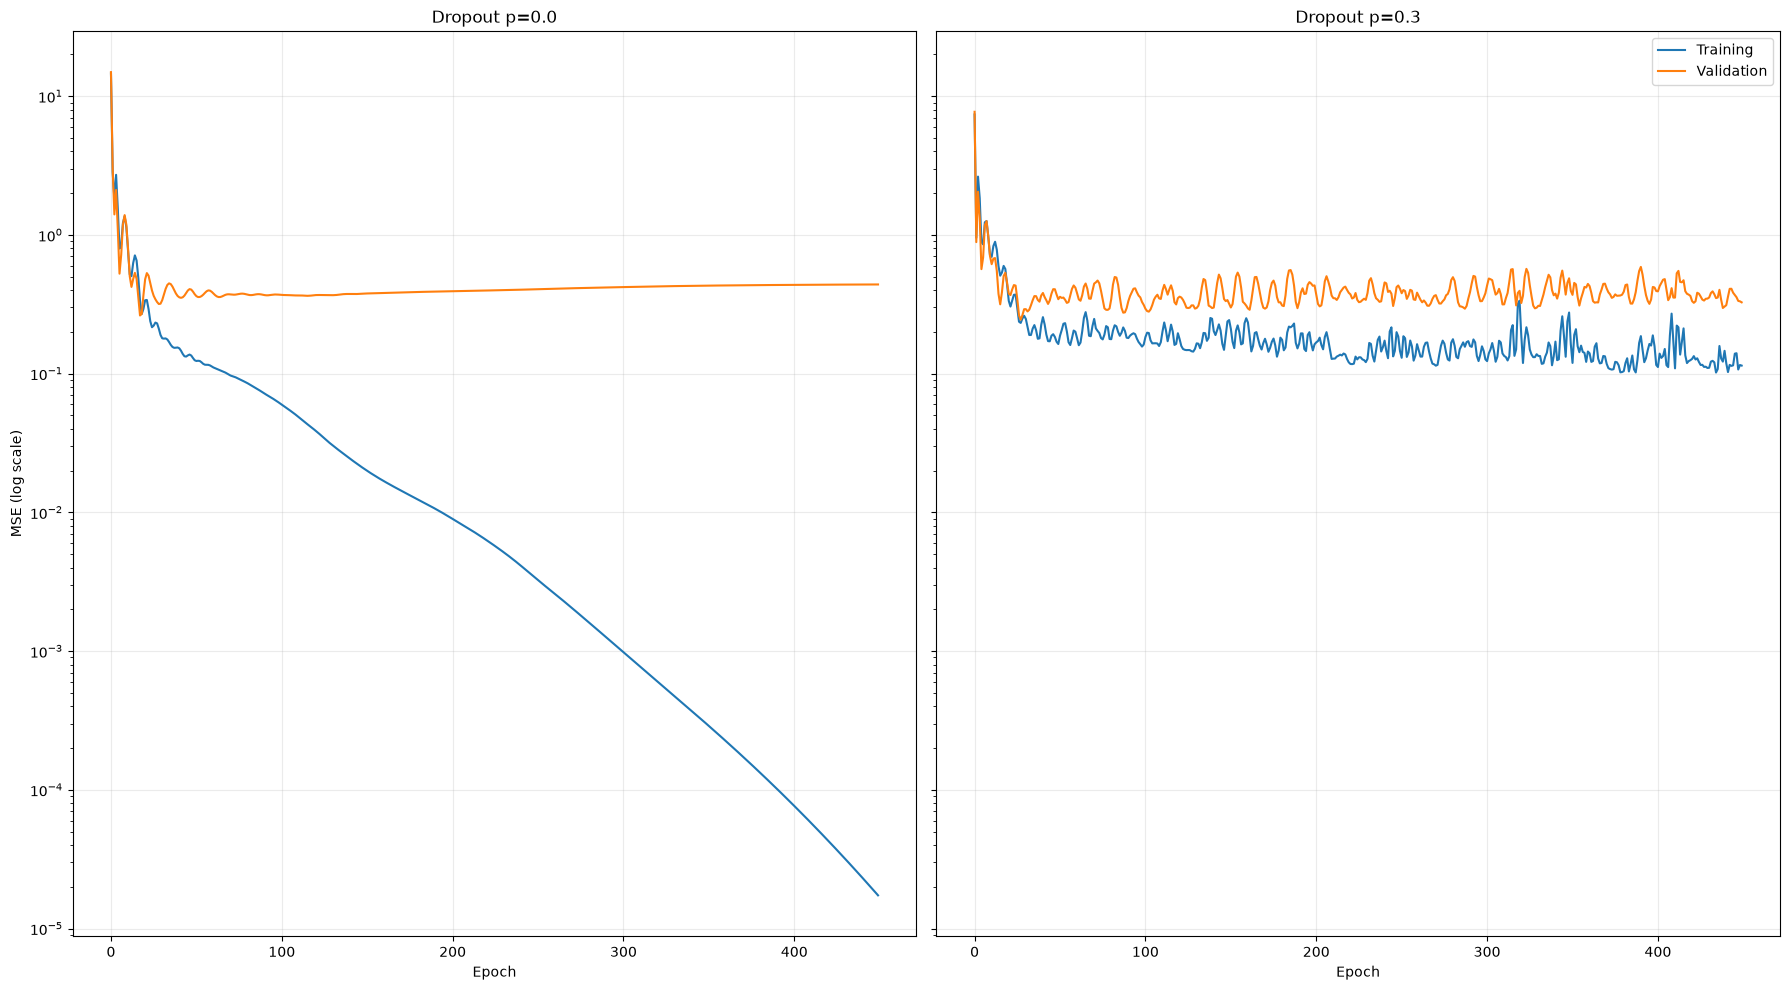

In [44]:
# Toggle dropout and compare train/validation curves on the same small dataset.
def fit_dropout(p, epochs=450):
    torch.manual_seed(SEED)
    net = nn.Sequential(nn.Linear(1, 128), nn.Tanh(), nn.Dropout(p),
                        nn.Linear(128, 128), nn.Tanh(), nn.Dropout(p), nn.Linear(128, 1))
    optimizer = torch.optim.Adam(net.parameters(), lr=0.015)
    train_losses, val_losses = [], []
    for _ in range(epochs):
        net.train(); optimizer.zero_grad()
        loss = nn.functional.mse_loss(net(x_train), y_train)
        loss.backward(); optimizer.step()
        net.eval()
        with torch.no_grad():
            train_losses.append(nn.functional.mse_loss(net(x_train), y_train).item())
            val_losses.append(nn.functional.mse_loss(net(x_val), y_val).item())
    return train_losses, val_losses
dropout_values = [0.0, 0.3]
fig, axes = plt.subplots(1, len(dropout_values), figsize=(18, 10), sharey=True)
for ax, p in zip(axes, dropout_values):
    train_loss, val_loss = fit_dropout(p)
    ax.plot(train_loss, label='Training')
    ax.plot(val_loss, label='Validation')
    ax.set_title(f'Dropout p={p}')
    ax.set_xlabel('Epoch')
    ax.set_yscale('log')
    ax.grid(alpha=0.25)
axes[0].set_ylabel('MSE (log scale)')
axes[-1].legend()
plt.tight_layout()
plt.show()

**Try it:** Change `p` to 0.1 and 0.7. Does stronger dropout always improve validation error? Explain the difference between a drop probability and a keep probability.

<details>
<summary><strong>Answer</strong></summary>

No. Stronger dropout does **not** always improve validation error. With `p=0.1`, the regularization is weak, so the model may still overfit. With `p=0.7`, 70% of the activations are removed during each training pass; this may be too aggressive and cause underfitting, increasing both training and validation error. The best value of `p` is a hyperparameter that should be selected using validation data, and the exact result can vary with the dataset and random seed.

In PyTorch, `nn.Dropout(p)` defines the **drop probability**:

$$P(\text{activation is dropped})=p.$$

The corresponding **keep probability** is

$$P(\text{activation is retained})=1-p.$$

Therefore, `p=0.1` keeps 90% of activations, whereas `p=0.7` keeps only 30%. During training, PyTorch scales retained activations by $1/(1-p)$ to preserve their expected magnitude. In `eval()` mode, dropout is disabled.

</details>

## 6 · CNNs: local filters, pooling, and parameter sharing
Images typically use tensor shape $(N,C,H,W)$ in PyTorch. A convolution applies a learned local filter across spatial positions, sharing its weights. For a 2D convolution with dilation 1, the spatial output dimension is

$$H_{out}=\left\lfloor\frac{H+2P-K}{S}\right\rfloor+1,$$

where $K$ is kernel size, $P$ padding, and $S$ stride (and similarly for width). A convolution has $C_{out}(C_{in}K_hK_w+1)$ parameters when biases are enabled. Pooling reduces spatial resolution.

In [45]:
# Inspect convolution shapes and parameter counts.
image_batch = torch.randn(4, 1, 28, 28)
conv = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1)
feature_maps = conv(image_batch)
pooled = nn.MaxPool2d(kernel_size=2)(feature_maps)
print('Input:', tuple(image_batch.shape))
print('Conv:', tuple(feature_maps.shape))
print('Pool:', tuple(pooled.shape))
print('Conv parameters:', sum(p.numel() for p in conv.parameters()))
assert pooled.shape == (4, 8, 14, 14)

Input: (4, 1, 28, 28)
Conv: (4, 8, 28, 28)
Pool: (4, 8, 14, 14)
Conv parameters: 80


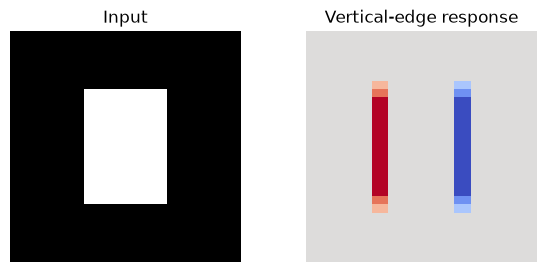

In [46]:
# See how a handcrafted edge filter responds to a simple image.
img = torch.zeros(1, 1, 28, 28)
img[:, :, 7:21, 9:19] = 1
edge = nn.Conv2d(1, 1, kernel_size=3, padding=1, bias=False)
with torch.no_grad():
    edge.weight.copy_(torch.tensor([[[[-1., 0., 1.], [-1., 0., 1.], [-1., 0., 1.]]]]))
    response = edge(img)
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(img[0,0], cmap='gray'); axes[0].set_title('Input')
axes[1].imshow(response[0,0], cmap='coolwarm'); axes[1].set_title('Vertical-edge response')
for ax in axes: ax.axis('off')
plt.show()

### A compact CNN classifier
Convolution extracts spatial features; nonlinearities allow richer features; pooling reduces resolution; a final classifier maps features to class logits. The example below trains on **synthetic images** (vertical vs. horizontal bars), so it runs offline.

In [47]:
def bar_data(n=600, size=16):
    images = torch.randn(n, 1, size, size)*0.15
    labels = torch.randint(0, 2, (n,))
    for i in range(n):
        position = int(torch.randint(3, size-3, (1,)).item())
        if labels[i] == 0: images[i, 0, :, position-1:position+1] += 1  # vertical
        else: images[i, 0, position-1:position+1, :] += 1             # horizontal
    return images, labels
Xbar, ybar = bar_data()
train_loader = DataLoader(TensorDataset(Xbar[:480], ybar[:480]), batch_size=32, shuffle=True)
Xbar_test, ybar_test = Xbar[480:], ybar[480:]
cnn = nn.Sequential(nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
                    nn.Flatten(), nn.Linear(16, 2))
optimizer = torch.optim.Adam(cnn.parameters(), lr=0.01)
for epoch in range(8):
    cnn.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = nn.functional.cross_entropy(cnn(xb), yb)
        loss.backward(); optimizer.step()
cnn.eval()
with torch.no_grad():
    accuracy = (cnn(Xbar_test).argmax(1) == ybar_test).float().mean().item()
print(f'CNN held-out accuracy: {accuracy:.1%}')
print('Trainable parameters:', sum(p.numel() for p in cnn.parameters()))

CNN held-out accuracy: 100.0%
Trainable parameters: 1282


<details>
<summary><strong>Notes</strong></summary>

### Trainable parameters

For a convolution with a bias, the parameter count is

$$C_{out}(C_{in}K_hK_w+1),$$

where the $+1$ represents one bias per output channel. For a linear layer, the count is $N_{out}(N_{in}+1)$. Therefore:

- `Conv2d(1, 8, 3)`: $8(1\times3\times3+1)=80$ parameters.
- `Conv2d(8, 16, 3)`: $16(8\times3\times3+1)=1{,}168$ parameters.
- `Linear(16, 2)`: $2(16+1)=34$ parameters.
- `ReLU`, pooling, adaptive pooling, and `Flatten` have no trainable parameters.

The total is therefore $80+1{,}168+34=\mathbf{1{,}282}$ trainable parameters.

### Why held-out accuracy can reach 100%

This synthetic classification problem is intentionally easy. The two classes contain visually distinct bright vertical or horizontal bars, the added noise is relatively small, and all training and held-out images come from exactly the same generator. Convolutional filters are well suited to detecting local orientations, weight sharing lets a learned detector work at every bar position, and pooling makes the prediction less sensitive to the bar's exact location. With 480 training examples, this small CNN can therefore learn a reliable decision rule in only a few epochs.

The held-out set contains only 120 images, so 100% accuracy means that all 120 generated examples were classified correctly. It does not prove that the model will be perfect on every future image or on images from a different distribution.

</details>

## 7 · Residual connections (brief introduction)
A residual block learns $F(x)$ and outputs $x+F(x)$. The skip path gives gradients an additional route through a deep network. The tensors being added must have compatible shapes; projection shortcuts can handle dimension changes. You will learn the details in the course. 

In [48]:
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.f = nn.Sequential(nn.Conv2d(channels, channels, 3, padding=1), nn.ReLU(),
                               nn.Conv2d(channels, channels, 3, padding=1))
        self.activation = nn.ReLU()
    def forward(self, x):
        return self.activation(x + self.f(x))
block = ResidualBlock(8)
print('Residual block output:', tuple(block(torch.randn(4, 8, 16, 16)).shape))

Residual block output: (4, 8, 16, 16)


## Final review · Questions and experiments
1. Explain the difference between a **parameter**, a **gradient**, and a **learning rate**.
2. Write the five lines of a standard PyTorch training iteration from memory.
3. For 1,000 training samples and batch size 64, how many parameter updates occur in one epoch?
4. Distinguish **training**, **validation**, and **test** error. Why is model selection based on the test set problematic?
5. What evidence in learning curves suggests overfitting? Name two possible remedies.
6. What is the difference between dropout's behavior in `train()` and `eval()` modes?
7. Compute the output shape and parameter count of `nn.Conv2d(3, 16, 3, stride=2, padding=1)` for input `(32,3,64,64)`.
8. Why are CNNs more parameter-efficient than fully connected layers on large images?

**Optional coding challenge:** modify the bar-image CNN to include dropout; compare validation accuracy for `p=0`, `0.2`, and `0.5` across three random seeds. Report the average and variability, not just one run.

<details>
<summary><strong>Answers</strong></summary>

1. A **parameter** is a learnable value in the model, such as a weight or bias. A **gradient** is the derivative of the loss with respect to a parameter; it indicates how changing that parameter would change the loss. The **learning rate** is a hyperparameter that scales the optimizer's update, controlling the step size taken using the gradient.

2. A standard five-line PyTorch training iteration is:

   ```python
   optimizer.zero_grad()
   predictions = model(inputs)
   loss = loss_fn(predictions, targets)
   loss.backward()
   optimizer.step()
   ```

3. With the default `drop_last=False`, there are $\lceil 1000/64 \rceil = 16$ batches, so there are **16 parameter updates** in one epoch. (With `drop_last=True`, there would be 15.)

4. **Training error** is measured on data used to fit the parameters. **Validation error** is measured on separate data used to choose models and hyperparameters, including when to stop training. **Test error** is measured once on untouched data to estimate final generalization. Selecting a model using the test set leaks information from that set into the choice, so the reported test performance becomes optimistically biased and is no longer an independent estimate.

5. Overfitting is suggested when training loss keeps decreasing (or training accuracy keeps increasing) while validation loss begins increasing (or validation accuracy stalls or decreases), producing a widening train-validation gap. Two remedies are **early stopping** and **regularization**, such as weight decay or dropout.

6. In `train()` mode, dropout randomly zeros activations with probability $p$ and scales the surviving activations by $1/(1-p)$. In `eval()` mode, dropout is disabled, so activations pass through unchanged.

7. The spatial size is $\left\lfloor(64 + 2(1) - 3)/2\right\rfloor + 1 = 32$, so the output shape is **`(32, 16, 32, 32)`**. With the default bias, the parameter count is $16(3\times3\times3 + 1) = \mathbf{448}$: 432 weights and 16 biases.

8. CNNs use **local connectivity** and **weight sharing**: the same small kernel is applied at every spatial location. Their parameter count therefore depends on kernel size and channel counts, not directly on image height and width. A fully connected layer gives each output unit a separate weight for every input pixel, so its parameter count grows rapidly with image size.

</details>